# Hello ISRO Keyword Spotting — Classical Machine Learning

This notebook uses the existing `../training` and `../testing` WAV files. It performs data cleaning, focused EDA, MFCC feature engineering, classical model comparison, ensembles, GridSearchCV tuning, INT8 input quantization, and HistGradientBoosting C/H export for ESP32-S3.


## 2. Imports and project settings

Audio is standardized to **16,000 Hz**, **1.0 second** (16,000 samples). MFCC uses 13 coefficients, a 480-sample window, 160-sample hop and 512-point FFT; the matrix shape is **13 × 101**.


In [2]:
from pathlib import Path
import json, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa, joblib
from scipy.signal import resample_poly
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier, StackingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings('ignore')
SEED=42; random.seed(SEED); np.random.seed(SEED)
TRAIN_DIR=Path('../training'); TEST_DIR=Path('../testing'); OUT=Path('hello_isro_outputs')
for folder in ['reports','plots','features','models','metrics']: (OUT/folder).mkdir(parents=True,exist_ok=True)
LABELS=['HelloISRO','Others','Noise']; LABEL_TO_ID={label:i for i,label in enumerate(LABELS)}
SR=16000; WINDOW=16000; N_MFCC=13; N_FFT=512; HOP=160; WIN=480; FRAMES=101
print('Training:',TRAIN_DIR.resolve(),'| Testing:',TEST_DIR.resolve())


Training: D:\sih\project\training | Testing: D:\sih\project\testing


## 3. Collect files and derive labels

Files beginning with `hello isro` or `hello_isro` are **HelloISRO**. Files beginning with `noise` or `silence` are **Noise**. Every other file, including `unknown...`, becomes **Others**. Inspect the table before training; correct the rule here if your filenames use another convention.


In [3]:
def label_from_name(name):
    name=name.lower().replace('_',' ').replace('-',' ')
    if name.startswith('hello isro') or name.startswith('helloisro'): return 'HelloISRO'
    if name.startswith('noise') or name.startswith('silence'): return 'Noise'
    return 'Others'

rows=[]
for split,folder in [('train',TRAIN_DIR),('test',TEST_DIR)]:
    for path in sorted(folder.rglob('*.wav')):
        info=sf.info(path); rows.append({'path':str(path),'split':split,'label':label_from_name(path.name),'sample_rate':info.samplerate,'samples':info.frames,'seconds':info.frames/info.samplerate})
manifest=pd.DataFrame(rows); manifest['label_id']=manifest.label.map(LABEL_TO_ID)
if manifest.empty: raise FileNotFoundError('No WAV files found. Check TRAIN_DIR and TEST_DIR.')
manifest.to_csv(OUT/'reports'/'dataset_manifest.csv',index=False)
display(manifest.groupby(['split','label']).size().unstack(fill_value=0))
print('Total WAV files:',len(manifest))


label,HelloISRO,Noise,Others
split,,,
test,82,149,153
train,406,579,565


Total WAV files: 1934


## 3A. Data cleaning and validation

This step checks that every WAV file is readable and has a positive number of frames, sample rate and channel count. Invalid files are excluded before analysis or training. A report is saved so the decision is auditable. No valid recording is silently removed.


In [4]:
checks=[]
for row in manifest.itertuples(index=False):
    try:
        info=sf.info(row.path)
        valid=info.frames>0 and info.samplerate>0 and info.channels>0
        reason='' if valid else 'empty audio or invalid audio metadata'
    except Exception as error:
        valid=False; reason=str(error)
    checks.append({'path':row.path,'valid':valid,'reason':reason})
cleaning_report=pd.DataFrame(checks)
cleaning_report.to_csv(OUT/'reports'/'data_cleaning_report.csv',index=False)
invalid_paths=set(cleaning_report.loc[~cleaning_report.valid,'path'])
manifest=manifest[~manifest.path.isin(invalid_paths)].reset_index(drop=True)
manifest.to_csv(OUT/'reports'/'dataset_manifest_clean.csv',index=False)
print('Valid files:',len(manifest),'| Removed invalid files:',len(invalid_paths))
display(cleaning_report.groupby(['valid','reason'],dropna=False).size().reset_index(name='files'))


Valid files: 1934 | Removed invalid files: 0


,valid,reason,files
0,True,,1934


## 4. Data analysis

These plots show class balance, original sample rates and clip duration. Class imbalance affects accuracy, so macro-F1 is used to compare models.


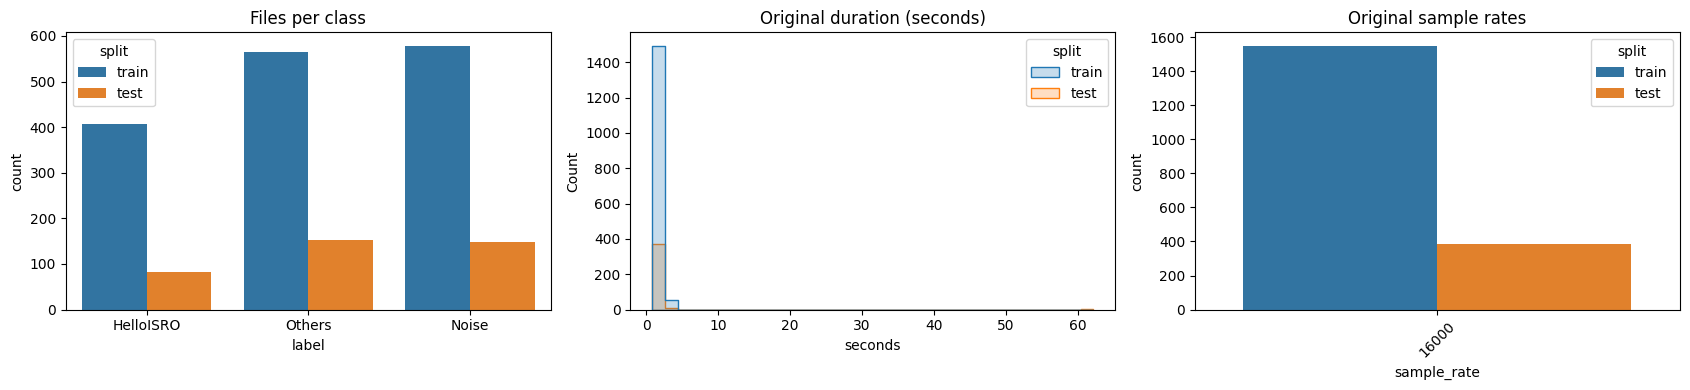

,files,mean_seconds,min_seconds,max_seconds
label,,,,
HelloISRO,488,1.884824,0.84675,3.024000
Noise,728,1.084002,1.00000,62.153500
Others,718,1.005664,1.00000,2.641188


In [5]:
fig,axes=plt.subplots(1,3,figsize=(17,4))
sns.countplot(data=manifest,x='label',hue='split',order=LABELS,ax=axes[0]); axes[0].set_title('Files per class')
sns.histplot(data=manifest,x='seconds',hue='split',bins=35,element='step',ax=axes[1]); axes[1].set_title('Original duration (seconds)')
sns.countplot(data=manifest,x='sample_rate',hue='split',ax=axes[2]); axes[2].set_title('Original sample rates'); axes[2].tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.savefig(OUT/'plots'/'dataset_analysis.png',dpi=150); plt.show()
display(manifest.groupby('label').agg(files=('path','count'),mean_seconds=('seconds','mean'),min_seconds=('seconds','min'),max_seconds=('seconds','max')))


## 4A. Windowing impact: relevant input-quality EDA

The model always receives one second. This graph shows how many source recordings are cropped, padded or already one second long in each class. It is important because a long noise clip or a short keyword clip can change the information that reaches the model.


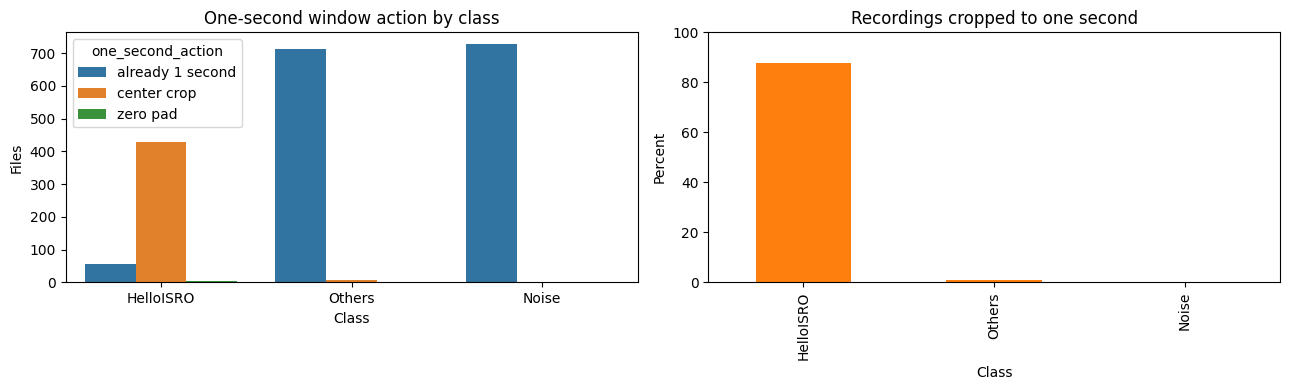

one_second_action,already 1 second,center crop,zero pad
label,,,
HelloISRO,57,428,3
Others,712,6,0
Noise,727,1,0


In [6]:
windowing=manifest[['label','split','seconds']].copy()
windowing['one_second_action']=np.where(windowing.seconds>1.0,'center crop',np.where(windowing.seconds<1.0,'zero pad','already 1 second'))
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.countplot(data=windowing,x='label',hue='one_second_action',order=LABELS,ax=axes[0]); axes[0].set_title('One-second window action by class'); axes[0].set_xlabel('Class'); axes[0].set_ylabel('Files')
crop_share=windowing.assign(cropped=windowing.one_second_action.eq('center crop')).groupby('label',observed=True).cropped.mean().reindex(LABELS).mul(100)
crop_share.plot(kind='bar',color='tab:orange',ax=axes[1]); axes[1].set_title('Recordings cropped to one second'); axes[1].set_xlabel('Class'); axes[1].set_ylabel('Percent'); axes[1].set_ylim(0,100)
plt.tight_layout(); plt.savefig(OUT/'plots'/'windowing_impact.png',dpi=150); plt.show()
display(windowing.groupby(['label','one_second_action']).size().unstack(fill_value=0).reindex(LABELS))


## 5. Audio processing and standardization

This processing step converts multichannel audio to mono, resamples it to 16 kHz, center-crops clips longer than one second, zero-pads shorter clips, and peak-normalizes the final 16,000-sample waveform. The same order and settings must be used on the ESP32.


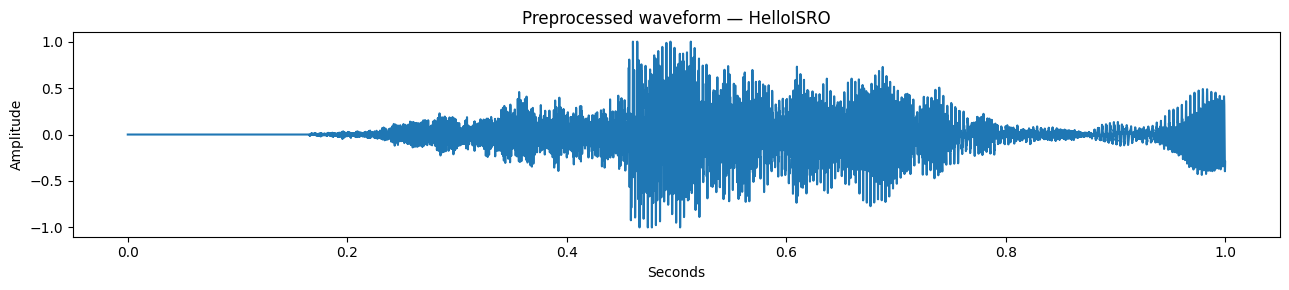

Standardized waveform: (16000,) samples | window: 1.0 second | sample rate: 16000 Hz


In [7]:
def load_one_second(path):
    audio,source_sr=sf.read(path,dtype='float32',always_2d=True); audio=audio.mean(axis=1)
    if source_sr!=SR: audio=resample_poly(audio,SR,source_sr).astype(np.float32)
    if len(audio)>WINDOW:
        start=(len(audio)-WINDOW)//2; audio=audio[start:start+WINDOW]
    else:
        pad=WINDOW-len(audio); audio=np.pad(audio,(pad//2,pad-pad//2))
    return audio/np.maximum(np.max(np.abs(audio)),1e-6)

example=manifest.iloc[0]; wave=load_one_second(example.path); time=np.arange(WINDOW)/SR
plt.figure(figsize=(13,3)); plt.plot(time,wave); plt.title(f'Preprocessed waveform — {example.label}'); plt.xlabel('Seconds'); plt.ylabel('Amplitude'); plt.tight_layout(); plt.show()
print('Standardized waveform:',wave.shape,'samples | window:',WINDOW/SR,'second | sample rate:',SR,'Hz')


## 6. MFCC feature generation

Each recording is represented by a 13 × 101 MFCC matrix. Classical models use a 52-value summary: mean, standard deviation, minimum and maximum for each of 13 MFCC coefficients.


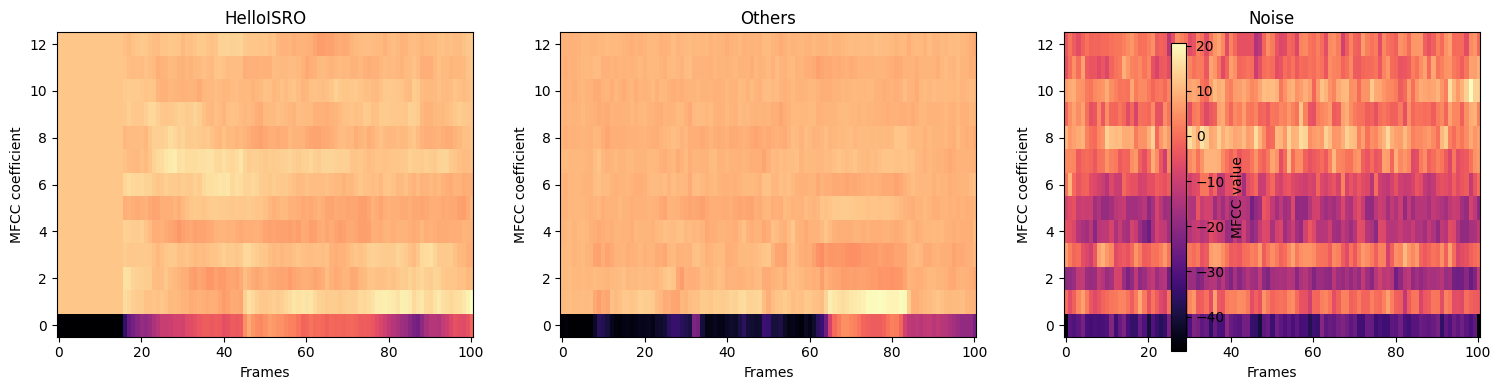

MFCC matrix: (13, 101) | Classical summary feature size: 52


In [8]:
def mfcc_matrix(path):
    audio=load_one_second(path)
    matrix=librosa.feature.mfcc(y=audio,sr=SR,n_mfcc=N_MFCC,n_fft=N_FFT,hop_length=HOP,win_length=WIN,n_mels=40,fmin=20,fmax=4000,center=True)
    matrix=np.pad(matrix,((0,0),(0,max(0,FRAMES-matrix.shape[1]))))[:,:FRAMES]
    return matrix.astype(np.float32)

mfcc_examples={}
for label in LABELS:
    path=manifest[(manifest.split=='train')&(manifest.label==label)].iloc[0].path; mfcc_examples[label]=mfcc_matrix(path)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,label in zip(axes,LABELS):
    image=ax.imshow(mfcc_examples[label],origin='lower',aspect='auto',cmap='magma'); ax.set_title(label); ax.set_xlabel('Frames'); ax.set_ylabel('MFCC coefficient')
fig.colorbar(image,ax=axes.ravel().tolist(),label='MFCC value'); plt.tight_layout(); plt.savefig(OUT/'plots'/'mfcc_by_class.png',dpi=150); plt.show()
print('MFCC matrix:',mfcc_examples[LABELS[0]].shape,'| Classical summary feature size:',N_MFCC*4)


## 6A. Additional input-feature analysis

These plots compare waveform shape and mel-spectrogram energy for one standardized training recording from every class. They help verify whether the input sound patterns are visibly different before training.


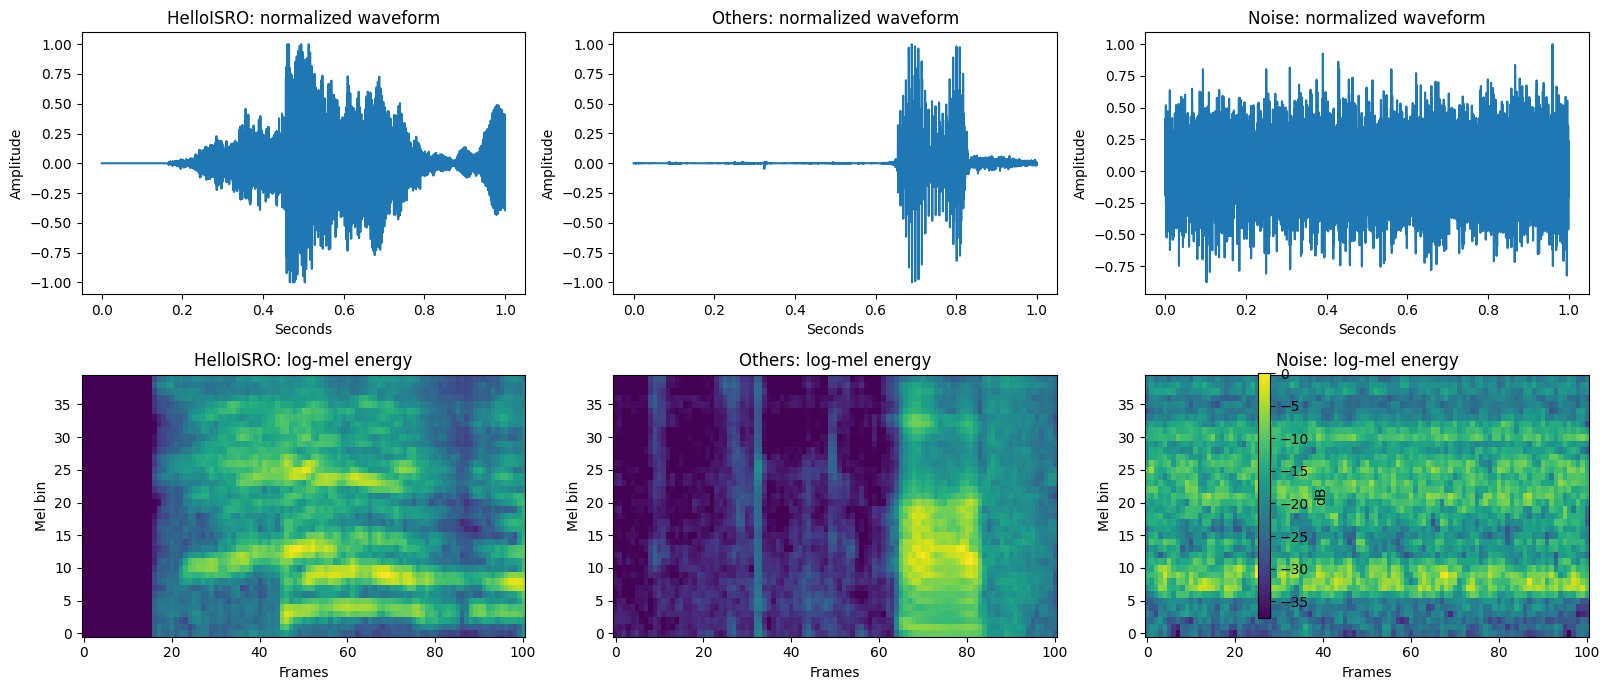

Input settings: mono | 16,000 Hz | 1.0 second | 512 FFT | 480-sample window | 160-sample hop | 40 mel bands | 13 MFCC coefficients


In [9]:
fig,axes=plt.subplots(2,3,figsize=(16,7))
for column,label in enumerate(LABELS):
    path=manifest[(manifest.split=='train')&(manifest.label==label)].iloc[0].path; audio=load_one_second(path)
    axes[0,column].plot(np.arange(WINDOW)/SR,audio,color='tab:blue'); axes[0,column].set(title=f'{label}: normalized waveform',xlabel='Seconds',ylabel='Amplitude')
    mel=librosa.feature.melspectrogram(y=audio,sr=SR,n_fft=N_FFT,hop_length=HOP,n_mels=40,fmin=20,fmax=4000,power=2.0)
    image=axes[1,column].imshow(librosa.power_to_db(mel,ref=np.max),origin='lower',aspect='auto',cmap='viridis'); axes[1,column].set(title=f'{label}: log-mel energy',xlabel='Frames',ylabel='Mel bin')
fig.colorbar(image,ax=axes[1,:].ravel().tolist(),label='dB'); plt.tight_layout(); plt.savefig(OUT/'plots'/'waveform_and_mel_by_class.png',dpi=150); plt.show()
print('Input settings: mono | 16,000 Hz | 1.0 second | 512 FFT | 480-sample window | 160-sample hop | 40 mel bands | 13 MFCC coefficients')


## 7. Build and save feature arrays

This cell processes each WAV once and saves the arrays, so later experiments can start from the saved MFCC features. It may take several minutes.


In [10]:
summaries=[]
for n,row in enumerate(manifest.itertuples(index=False),1):
    matrix=mfcc_matrix(row.path)
    summaries.append(np.concatenate([matrix.mean(1),matrix.std(1),matrix.min(1),matrix.max(1)]))
    if n%200==0: print(f'Processed {n}/{len(manifest)}')
X_classical=np.asarray(summaries,np.float32); y=manifest.label_id.to_numpy(np.int32)
np.save(OUT/'features'/'mfcc_summary_features.npy',X_classical); np.save(OUT/'features'/'labels.npy',y)
train_mask=manifest.split.eq('train').to_numpy(); test_mask=~train_mask
Xtr,Xte=X_classical[train_mask],X_classical[test_mask]; ytr,yte=y[train_mask],y[test_mask]
print('Classical feature shape:',Xtr.shape,'| feature count:',Xtr.shape[1],'| train/test:',len(ytr),len(yte))


Processed 200/1934
Processed 400/1934
Processed 600/1934
Processed 800/1934
Processed 1000/1934
Processed 1200/1934
Processed 1400/1934
Processed 1600/1934
Processed 1800/1934
Classical feature shape: (1550, 52) | feature count: 52 | train/test: 1550 384


## 8. Train classical models

The models use the same training/test split supplied in your folders. SVM benefits from scaling; tree models do not require it.


In [11]:
models={
 'SVM':Pipeline([('scale',StandardScaler()),('model',SVC(C=8,kernel='rbf',probability=True,class_weight='balanced',random_state=SEED))]),
 'RandomForest':RandomForestClassifier(n_estimators=350,min_samples_leaf=1,class_weight='balanced',n_jobs=-1,random_state=SEED),
 'ExtraTrees':ExtraTreesClassifier(n_estimators=350,class_weight='balanced',n_jobs=-1,random_state=SEED),
 'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=250,learning_rate=.08,l2_regularization=.1,random_state=SEED),
 'AdaBoost':AdaBoostClassifier(n_estimators=250,learning_rate=.5,random_state=SEED),
 'DecisionTree':DecisionTreeClassifier(max_depth=18,class_weight='balanced',random_state=SEED) }
results=[]; fitted={}
for name,model in models.items():
    model.fit(Xtr,ytr); prediction=model.predict(Xte); fitted[name]=model
    results.append({'model':name,'test_accuracy':accuracy_score(yte,prediction),'test_macro_f1':f1_score(yte,prediction,average='macro')})
results=pd.DataFrame(results).sort_values(['test_macro_f1','test_accuracy'],ascending=False).reset_index(drop=True); display(results); results.to_csv(OUT/'metrics'/'classical_model_comparison.csv',index=False)


,model,test_accuracy,test_macro_f1
0,HistGradientBoosting,0.906250,0.912133
1,SVM,0.903646,0.909966
2,ExtraTrees,0.903646,0.909908
3,RandomForest,0.898438,0.904602
4,DecisionTree,0.830729,0.831949
5,AdaBoost,0.807292,0.803418


## 9. Ensemble models

Voting averages probabilities. Stacking learns how to combine the strongest individual models. Both are evaluated on the untouched testing folder.


In [12]:
ensemble_members=[('svm',models['SVM']),('extra',models['ExtraTrees']),('hist',models['HistGradientBoosting'])]
ensembles={
 'SoftVoting':VotingClassifier(estimators=ensemble_members,voting='soft',n_jobs=-1),
 'Stacking':StackingClassifier(estimators=ensemble_members,final_estimator=LogisticRegression(max_iter=2000,class_weight='balanced'),cv=4,n_jobs=-1) }
for name,model in ensembles.items():
    model.fit(Xtr,ytr); prediction=model.predict(Xte); fitted[name]=model
    results.loc[len(results)]={'model':name,'test_accuracy':accuracy_score(yte,prediction),'test_macro_f1':f1_score(yte,prediction,average='macro')}
results=results.sort_values(['test_macro_f1','test_accuracy'],ascending=False).reset_index(drop=True); display(results)


,model,test_accuracy,test_macro_f1
0,HistGradientBoosting,0.906250,0.912133
1,SVM,0.903646,0.909966
2,ExtraTrees,0.903646,0.909908
3,RandomForest,0.898438,0.904602
4,SoftVoting,0.898438,0.904600
5,Stacking,0.888021,0.889534
6,DecisionTree,0.830729,0.831949
7,AdaBoost,0.807292,0.803418


## 10. Tune the strongest classical approach

GridSearchCV automatically selects the highest-scoring individual classical model from the comparison and searches suitable hyperparameters using five-fold stratified cross-validation on the training folder only. The final testing folder remains untouched while parameters are chosen.


In [13]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
base_names=['SVM','RandomForest','ExtraTrees','HistGradientBoosting','AdaBoost','DecisionTree']
best_base=results[results.model.isin(base_names)].iloc[0].model
if best_base=='SVM':
    search_estimator=Pipeline([('scale',StandardScaler()),('model',SVC(probability=True,class_weight='balanced',random_state=SEED))]); search_grid={'model__C':[1,3,8,20],'model__gamma':['scale',.001,.003,.01]}
elif best_base=='ExtraTrees':
    search_estimator=ExtraTreesClassifier(class_weight='balanced',n_jobs=-1,random_state=SEED); search_grid={'n_estimators':[300,500],'max_features':['sqrt',.5,1.0],'min_samples_leaf':[1,2,4]}
elif best_base=='RandomForest':
    search_estimator=RandomForestClassifier(class_weight='balanced',n_jobs=-1,random_state=SEED); search_grid={'n_estimators':[300,500],'max_features':['sqrt',.5],'min_samples_leaf':[1,2,4]}
elif best_base=='HistGradientBoosting':
    search_estimator=HistGradientBoostingClassifier(random_state=SEED); search_grid={'max_iter':[150,250,350],'learning_rate':[.03,.08,.12],'l2_regularization':[0,.05,.2]}
elif best_base=='AdaBoost':
    search_estimator=AdaBoostClassifier(random_state=SEED); search_grid={'n_estimators':[150,250,350],'learning_rate':[.1,.5,1.0]}
else:
    search_estimator=DecisionTreeClassifier(class_weight='balanced',random_state=SEED); search_grid={'max_depth':[8,12,18,None],'min_samples_leaf':[1,2,4,8]}
grid=GridSearchCV(search_estimator,param_grid=search_grid,scoring='f1_macro',cv=cv,n_jobs=-1,verbose=1)
grid.fit(Xtr,ytr); tuned_classical=grid.best_estimator_; classical_pred=tuned_classical.predict(Xte)
print('Tuned base model:',best_base,'| Best CV macro-F1:',grid.best_score_,'| Parameters:',grid.best_params_)
print('Final test accuracy:',accuracy_score(yte,classical_pred),'| macro-F1:',f1_score(yte,classical_pred,average='macro'))
joblib.dump(tuned_classical,OUT/'models'/'best_classical_hello_isro.joblib')
print('Saved classical model:',OUT/'models'/'best_classical_hello_isro.joblib')


Fitting 5 folds for each of 27 candidates, totalling 135 fits
Tuned base model: HistGradientBoosting | Best CV macro-F1: 0.9340925454931966 | Parameters: {'l2_regularization': 0.05, 'learning_rate': 0.12, 'max_iter': 250}
Final test accuracy: 0.9010416666666666 | macro-F1: 0.9059726953719359
Saved classical model: hello_isro_outputs\models\best_classical_hello_isro.joblib


## 10A. Final classification report for the selected model

This evaluation uses the untouched testing folder. It reports overall accuracy and macro/weighted precision, recall and F1-score. Macro averages are the main result because each class—HelloISRO, Others and Noise—has equal importance. The confusion matrix shows the exact class-wise errors.


Best Model: HistGradientBoosting
Accuracy : 0.9010
Precision: 0.9008
Recall   : 0.9124
F1 Score : 0.9060


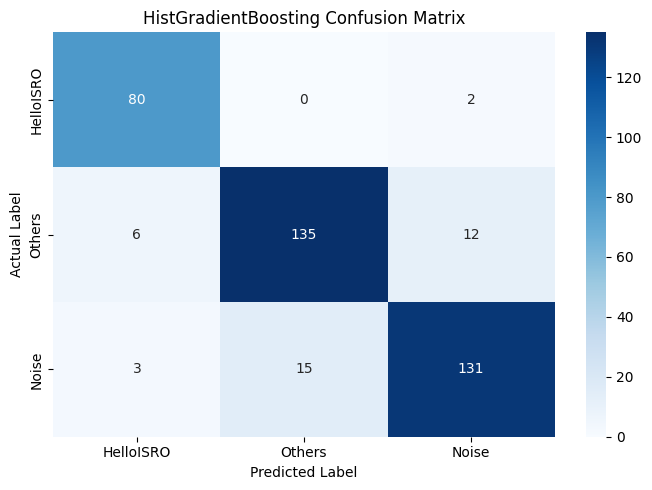

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Metrics for the selected HistGradientBoosting model
accuracy = accuracy_score(yte, classical_pred)
precision = precision_score(yte, classical_pred, average="macro", zero_division=0)
recall = recall_score(yte, classical_pred, average="macro", zero_division=0)
f1 = f1_score(yte, classical_pred, average="macro", zero_division=0)

print("Best Model:", best_base)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

# Confusion matrix
cm = confusion_matrix(yte, classical_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS
)
plt.title("HistGradientBoosting Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## 10B. Classical-model INT8 input quantization

This step quantizes each of the 52 MFCC-summary inputs to INT8 using calibration ranges from training data only. HistGradientBoosting tree thresholds and leaf values remain float, but the microphone feature buffer can be stored and transmitted as INT8 on the ESP32. The graph checks the accuracy and macro-F1 cost of quantization before deployment.


,version,test_accuracy,test_macro_f1
0,Float input,0.901042,0.905973
1,"INT8 input, dequantized",0.906250,0.911260


Float/INT8 prediction agreement: 99.48%


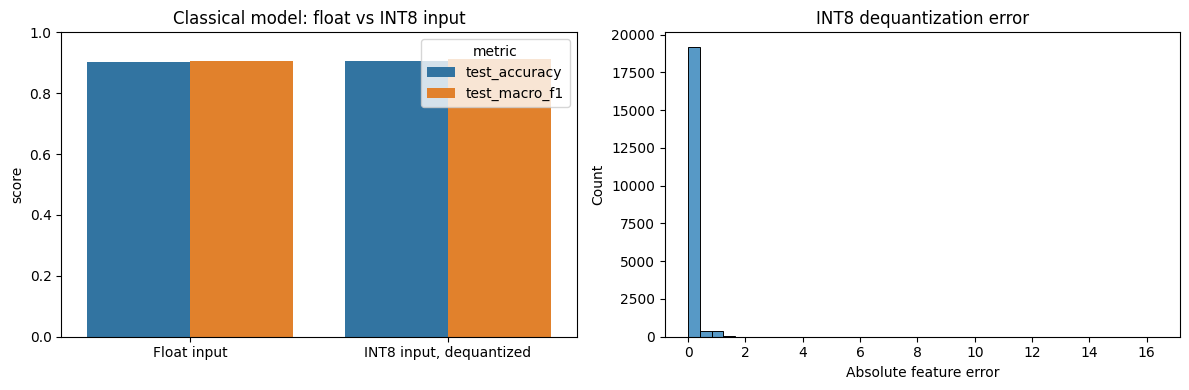

195

In [15]:
classical_q_min=Xtr.min(axis=0); classical_q_max=Xtr.max(axis=0)
classical_q_scale=np.maximum((classical_q_max-classical_q_min)/255.0,1e-8).astype(np.float32)
classical_q_zero=np.clip(np.rint(-classical_q_min/classical_q_scale-128),-128,127).astype(np.int16)
Xte_int8=np.clip(np.rint(Xte/classical_q_scale+classical_q_zero),-128,127).astype(np.int8)
Xte_dequant=(Xte_int8.astype(np.float32)-classical_q_zero)*classical_q_scale
quantized_classical_pred=tuned_classical.predict(Xte_dequant)
float_accuracy=accuracy_score(yte,classical_pred); float_f1=f1_score(yte,classical_pred,average='macro')
int8_accuracy=accuracy_score(yte,quantized_classical_pred); int8_f1=f1_score(yte,quantized_classical_pred,average='macro'); prediction_agreement=np.mean(classical_pred==quantized_classical_pred)
np.savez(OUT/'models'/'classical_input_int8_quantization.npz',scale=classical_q_scale,zero_point=classical_q_zero,feature_min=classical_q_min,feature_max=classical_q_max)
quantization_results=pd.DataFrame({'version':['Float input','INT8 input, dequantized'],'test_accuracy':[float_accuracy,int8_accuracy],'test_macro_f1':[float_f1,int8_f1]})
display(quantization_results); print('Float/INT8 prediction agreement:',f'{prediction_agreement:.2%}')
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=quantization_results.melt(id_vars='version',var_name='metric',value_name='score'),x='version',y='score',hue='metric',ax=axes[0]); axes[0].set_title('Classical model: float vs INT8 input'); axes[0].set_xlabel(''); axes[0].set_ylim(0,1)
absolute_error=np.abs(Xte-Xte_dequant).ravel(); sns.histplot(absolute_error,bins=40,ax=axes[1]); axes[1].set_title('INT8 dequantization error'); axes[1].set_xlabel('Absolute feature error')
plt.tight_layout(); plt.savefig(OUT/'plots'/'classical_int8_quantization.png',dpi=150); plt.show()
(OUT/'metrics'/'classical_int8_quantization.json').write_text(json.dumps({'float_accuracy':float(float_accuracy),'int8_accuracy':float(int8_accuracy),'float_macro_f1':float(float_f1),'int8_macro_f1':float(int8_f1),'prediction_agreement':float(prediction_agreement)},indent=2))


## 11. Classical ML outputs

After training and INT8-input evaluation, the selected classical model is saved as `hello_isro_outputs/models/best_classical_hello_isro.joblib`. The quantization ranges are saved in `classical_input_int8_quantization.npz` and metrics in `metrics/classical_int8_quantization.json`. Run the export cell next to generate `model.c` and `model.h` for the trained HistGradientBoosting model.


## 11. Classical-model deployment export

Run the following HistGradientBoosting exporter only after training and the INT8-input quantization evaluation. It creates `model.c`, `model.h`, and a validation report. The exported C model accepts the same 52 MFCC-summary features; its input can be either float or INT8.


In [16]:

"""
HistGradientBoostingClassifier -> ESP32-S3 C exporter.

Inputs:
  hello_isro_outputs/models/best_classical_hello_isro.joblib
  hello_isro_outputs/features/mfcc_summary_features.npy
  hello_isro_outputs/reports/dataset_manifest.csv

Outputs:
  hello_isro_outputs/models/model.c
  hello_isro_outputs/models/model.h
  hello_isro_outputs/models/model_export_report.json

IMPORTANT:
- Verify LABEL_MAP against your original training label encoder.
- Export is refused unless manual raw logits match scikit-learn.
- INT8 quantizes inputs only; tree calculations remain float.
"""

from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier


# ============================================================
# 1. CONFIGURATION
# ============================================================

OUT = Path("hello_isro_outputs")

MODEL_PATH = OUT / "models" / "best_classical_hello_isro.joblib"
FEATURE_PATH = OUT / "features" / "mfcc_summary_features.npy"
MANIFEST_PATH = OUT / "reports" / "dataset_manifest.csv"

MODEL_H = OUT / "models" / "model.h"
MODEL_C = OUT / "models" / "model.c"
REPORT_PATH = OUT / "models" / "model_export_report.json"

EXPECTED_FEATURES = 52
EXPECTED_NAMES = {"HelloISRO", "Noise", "Others"}

# Verify against the encoder used to train the model.
# LabelEncoder fitted to ["HelloISRO", "Noise", "Others"] gives
# 0=HelloISRO, 1=Others, 2=Noise.
LABEL_MAP = {
    "0": "HelloISRO",
    "1": "Others",
    "2": "Noise",
}

RAW_TOLERANCE = 1e-5
MIN_INT8_AGREEMENT = 0.99


# ============================================================
# 2. LOAD AND VALIDATE INPUTS
# ============================================================

for path in (MODEL_PATH, FEATURE_PATH, MANIFEST_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

model = joblib.load(MODEL_PATH)

if not isinstance(model, HistGradientBoostingClassifier):
    raise TypeError(
        f"Expected HistGradientBoostingClassifier, got "
        f"{type(model).__name__}"
    )

X = np.asarray(np.load(FEATURE_PATH), dtype=np.float32)
manifest = pd.read_csv(MANIFEST_PATH)

if X.ndim != 2:
    raise ValueError(f"Expected a 2D feature array; got {X.shape}")

if X.shape[1] != EXPECTED_FEATURES:
    raise ValueError(
        f"Expected {EXPECTED_FEATURES} features; found {X.shape[1]}"
    )

if X.shape[1] != model.n_features_in_:
    raise ValueError(
        f"Model expects {model.n_features_in_} features; "
        f"dataset has {X.shape[1]}"
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Feature array contains NaN or infinity. "
        "Clean features consistently with the training pipeline."
    )

if "split" not in manifest.columns:
    raise ValueError("Manifest requires a 'split' column.")

if len(manifest) != len(X):
    raise ValueError("Manifest row count does not match feature row count.")

splits = (
    manifest["split"].astype(str).str.strip().str.lower().to_numpy()
)

X_train = X[splits == "train"]
X_test = X[splits == "test"]

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Training and test splits must both be nonempty.")

MODEL_CLASSES = [str(c) for c in model.classes_]

if len(MODEL_CLASSES) != 3:
    raise ValueError(f"Expected 3 classes; found {MODEL_CLASSES}")

if set(MODEL_CLASSES) != set(LABEL_MAP):
    raise ValueError(
        f"model.classes_={MODEL_CLASSES}, but LABEL_MAP keys are "
        f"{list(LABEL_MAP)}. Fix LABEL_MAP using your training encoder."
    )

CLASS_NAMES = [LABEL_MAP[c] for c in MODEL_CLASSES]

if set(CLASS_NAMES) != EXPECTED_NAMES:
    raise ValueError(f"Incorrect mapped class names: {CLASS_NAMES}")

N_FEATURES = int(model.n_features_in_)
N_CLASSES = len(model.classes_)

print("\nModel:", type(model).__name__)
print("scikit-learn:", sklearn.__version__)
print("Model class order:", MODEL_CLASSES)
print("Firmware class labels:", CLASS_NAMES)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))


# ============================================================
# 3. READ MODEL TREE STRUCTURE
# ============================================================

# Private scikit-learn API: pin the version used for export.
stages = model._predictors
N_ITERATIONS = len(stages)
TREES_PER_ITERATION = int(model.n_trees_per_iteration_)
LEARNING_RATE = float(model.learning_rate)

BASE = np.asarray(
    model._baseline_prediction, dtype=np.float64
).reshape(-1)

if TREES_PER_ITERATION != N_CLASSES:
    raise ValueError(
        f"Expected {N_CLASSES} trees per iteration; "
        f"found {TREES_PER_ITERATION}"
    )

if len(BASE) != N_CLASSES:
    raise ValueError(f"Unexpected baseline shape: {BASE.shape}")

flat_trees = []

for iteration, stage in enumerate(stages):
    for class_id, predictor in enumerate(stage):
        nodes = predictor.nodes

        if np.any(nodes["is_categorical"]):
            raise ValueError("Categorical splits are not supported.")

        flat_nodes = []

        for node in nodes:
            flat_nodes.append({
                "value": float(node["value"]),
                "feature": int(node["feature_idx"]),
                "threshold": float(node["num_threshold"]),
                "left": int(node["left"]),
                "right": int(node["right"]),
                "missing_left": int(node["missing_go_to_left"]),
                "is_leaf": int(node["is_leaf"]),
            })

        flat_trees.append({
            "iteration": iteration,
            "class_id": class_id,
            "nodes": flat_nodes,
        })

print("Boosting iterations:", N_ITERATIONS)
print("Trees per iteration:", TREES_PER_ITERATION)
print("Total trees:", len(flat_trees))
print("Learning rate:", LEARNING_RATE)


# ============================================================
# 4. MANUAL TREE INFERENCE
# ============================================================

def manual_raw_prediction(samples, tree_multiplier):
    """Evaluate exported nodes and return raw class scores."""
    samples = np.asarray(samples, dtype=np.float32)

    if samples.ndim != 2 or samples.shape[1] != N_FEATURES:
        raise ValueError(f"Expected sample shape (N, {N_FEATURES})")

    scores = np.tile(BASE, (len(samples), 1)).astype(np.float64)

    for tree in flat_trees:
        class_id = tree["class_id"]
        nodes = tree["nodes"]

        for row_idx, sample in enumerate(samples):
            idx = 0
            steps = 0

            while not nodes[idx]["is_leaf"]:
                node = nodes[idx]
                value = float(sample[node["feature"]])

                if np.isnan(value):
                    go_left = bool(node["missing_left"])
                else:
                    go_left = value <= node["threshold"]

                idx = node["left"] if go_left else node["right"]
                steps += 1

                if steps > len(nodes):
                    raise RuntimeError("Invalid tree traversal.")

            scores[row_idx, class_id] += (
                tree_multiplier * nodes[idx]["value"]
            )

    return scores


# ============================================================
# 5. AUTO-DIAGNOSE LEARNING-RATE SEMANTICS
# ============================================================

# Test held-out rows distributed across the test set.
check_count = min(250, len(X_test))
indices = np.unique(
    np.linspace(0, len(X_test) - 1, check_count, dtype=int)
)
X_check = X_test[indices]

sklearn_raw = np.asarray(
    model._raw_predict(X_check), dtype=np.float64
)

if sklearn_raw.shape != (len(X_check), N_CLASSES):
    raise RuntimeError(
        f"Unexpected sklearn raw prediction shape: {sklearn_raw.shape}"
    )

# Candidate A: multiply leaf values by learning rate.
raw_scaled = manual_raw_prediction(X_check, LEARNING_RATE)
error_scaled = float(np.max(np.abs(sklearn_raw - raw_scaled)))

# Candidate B: use leaf values without an extra learning-rate factor.
raw_unscaled = manual_raw_prediction(X_check, 1.0)
error_unscaled = float(np.max(np.abs(sklearn_raw - raw_unscaled)))

print("\n--- Raw-logit validation ---")
print("Scaled-tree candidate error:", error_scaled)
print("Unscaled-tree candidate error:", error_unscaled)
print("Required maximum error:", RAW_TOLERANCE)

candidates = [
    ("learning_rate", LEARNING_RATE, error_scaled),
    ("unscaled", 1.0, error_unscaled),
]

valid = [
    candidate for candidate in candidates
    if np.isfinite(candidate[2]) and candidate[2] <= RAW_TOLERANCE
]

if not valid:
    print("\nFirst sample comparison:")
    print("scikit-learn:", sklearn_raw[0])
    print("scaled:", raw_scaled[0])
    print("unscaled:", raw_unscaled[0])

    print("\nMaximum per-class differences:")
    print("scaled:", np.max(np.abs(sklearn_raw - raw_scaled), axis=0))
    print("unscaled:", np.max(np.abs(sklearn_raw - raw_unscaled), axis=0))

    raise RuntimeError(
        "Neither tree-value interpretation matches scikit-learn. "
        "No C files were generated. Do not relax the tolerance. "
        "Inspect the printed scores, sklearn version, and tree traversal."
    )

# Prefer the conventional learning-rate interpretation if both pass.
chosen = min(valid, key=lambda c: 0 if c[0] == "learning_rate" else 1)
TREE_MULTIPLIER_NAME, TREE_MULTIPLIER, raw_error = chosen

print("Selected tree multiplier:", TREE_MULTIPLIER_NAME)
print("Validated raw-logit error:", raw_error)


# ============================================================
# 6. CALIBRATE PER-FEATURE INT8 INPUT QUANTIZATION
# ============================================================

feature_min = X_train.min(axis=0).astype(np.float64)
feature_max = X_train.max(axis=0).astype(np.float64)

Q_SCALE = np.maximum(
    (feature_max - feature_min) / 255.0, 1e-8
).astype(np.float32)

Q_ZERO = np.clip(
    np.rint(-128.0 - feature_min / Q_SCALE.astype(np.float64)),
    -128,
    127,
).astype(np.int16)


def quantize_features(samples):
    q = np.rint(
        np.asarray(samples, dtype=np.float32) / Q_SCALE + Q_ZERO
    )
    return np.clip(q, -128, 127).astype(np.int8)


def dequantize_features(samples):
    return (
        (
            np.asarray(samples, dtype=np.int16) - Q_ZERO
        ).astype(np.float32) * Q_SCALE
    ).astype(np.float32)


X_check_q = quantize_features(X_check)
X_check_dequant = dequantize_features(X_check_q)

float_predictions = model.predict(X_check)
quantized_raw = manual_raw_prediction(
    X_check_dequant, TREE_MULTIPLIER
)
quantized_predictions = model.classes_[
    np.argmax(quantized_raw, axis=1)
]

quantized_agreement = float(
    np.mean(float_predictions == quantized_predictions)
)

print("Float vs INT8-input agreement:", f"{quantized_agreement:.2%}")

if not np.isfinite(quantized_agreement):
    raise RuntimeError("Quantized-input agreement is invalid.")

if quantized_agreement < MIN_INT8_AGREEMENT:
    raise RuntimeError(
        f"Quantized-input agreement {quantized_agreement:.2%} is below "
        f"{MIN_INT8_AGREEMENT:.2%}. No C files generated. "
        "Review quantization quality before deployment."
    )


# ============================================================
# 7. C CODE HELPERS
# ============================================================

def c_float(value):
    value = float(value)

    if np.isnan(value):
        return "NAN"
    if np.isposinf(value):
        return "INFINITY"
    if np.isneginf(value):
        return "(-INFINITY)"

    result = format(value, ".9g")

    if "." not in result and "e" not in result.lower():
        result += ".0"

    return result + "f"


def c_string(value):
    return json.dumps(str(value), ensure_ascii=True)


# ============================================================
# 8. GENERATE model.h
# ============================================================

header = [
    "#ifndef KWS_HGB_MODEL_H",
    "#define KWS_HGB_MODEL_H",
    "#include <stdint.h>",
    "",
    f"#define KWS_HGB_FEATURE_COUNT {N_FEATURES}",
    f"#define KWS_HGB_CLASS_COUNT {N_CLASSES}",
    "",
    "extern const char * const "
    "kws_hgb_class_names[KWS_HGB_CLASS_COUNT];",
    "",
    "int kws_hgb_predict_class_float(const float *input, float *probabilities);",
    "void kws_hgb_quantize_features(const float *input, int8_t *output);",
    "int kws_hgb_predict_class_int8(const int8_t *input, float *probabilities);",
    "",
    "#endif",
]


# ============================================================
# 9. GENERATE model.c
# ============================================================

src = [
    '#include "model.h"',
    "#include <math.h>",
    "#include <stddef.h>",
    "#include <stdint.h>",
    "",
    "typedef struct {",
    " int16_t feature; float threshold;",
    " uint32_t left, right; float value;",
    " uint8_t missing_left, is_leaf;",
    "} HgbNode;",
    "",
    "typedef struct {",
    " const HgbNode *nodes; uint32_t count; uint8_t class_id;",
    "} HgbTree;",
    "",
    "const char * const kws_hgb_class_names[KWS_HGB_CLASS_COUNT] = {",
    " " + ", ".join(c_string(x) for x in CLASS_NAMES),
    "};",
    "",
    f"static const float tree_multiplier = {c_float(TREE_MULTIPLIER)};",
    "static const float base_logits[KWS_HGB_CLASS_COUNT] = {",
    " " + ", ".join(c_float(x) for x in BASE),
    "};",
    "static const float q_scale[KWS_HGB_FEATURE_COUNT] = {",
    " " + ", ".join(c_float(x) for x in Q_SCALE),
    "};",
    "static const int16_t q_zero[KWS_HGB_FEATURE_COUNT] = {",
    " " + ", ".join(str(int(x)) for x in Q_ZERO),
    "};",
    "",
]

tree_metadata = []

for ti, tree in enumerate(flat_trees):
    array_name = f"tree_{ti}"
    src.append(f"static const HgbNode {array_name}[] = {{")

    for node in tree["nodes"]:
        src.append(
            " {"
            + f"{node['feature']}, {c_float(node['threshold'])}, "
            + f"{node['left']}u, {node['right']}u, "
            + f"{c_float(node['value'])}, "
            + f"{node['missing_left']}, {node['is_leaf']}"
            + "},"
        )

    src.extend(["};", ""])
    tree_metadata.append(
        (array_name, len(tree["nodes"]), tree["class_id"])
    )

src.append("static const HgbTree trees[] = {")

for name, count, class_id in tree_metadata:
    src.append(f" {{{name}, {count}u, {class_id}}},")

src.extend([
    "};",
    f"static const uint32_t tree_count = {len(tree_metadata)}u;",
    "",
    "static void softmax(const float *z, float *p) {",
    " float mx = z[0], sum = 0.0f;",
    " for (int c=1; c<KWS_HGB_CLASS_COUNT; ++c)",
    "  if (z[c] > mx) mx = z[c];",
    " for (int c=0; c<KWS_HGB_CLASS_COUNT; ++c) {",
    "  p[c] = expf(z[c]-mx); sum += p[c];",
    " }",
    " if (!(sum > 0.0f) || !isfinite(sum)) {",
    "  for (int c=0; c<KWS_HGB_CLASS_COUNT; ++c)",
    "   p[c] = 1.0f/(float)KWS_HGB_CLASS_COUNT;",
    "  return;",
    " }",
    " for (int c=0; c<KWS_HGB_CLASS_COUNT; ++c) p[c] /= sum;",
    "}",
    "",
    "static float tree_float(const HgbTree *t, const float *x) {",
    " uint32_t i=0u;",
    " while (!t->nodes[i].is_leaf) {",
    "  const HgbNode *n=&t->nodes[i]; float v=x[n->feature];",
    "  if (isnan(v)) i=n->missing_left ? n->left : n->right;",
    "  else i=(v <= n->threshold) ? n->left : n->right;",
    " }",
    " return t->nodes[i].value;",
    "}",
    "",
    "static float tree_int8(const HgbTree *t, const int8_t *x) {",
    " uint32_t i=0u;",
    " while (!t->nodes[i].is_leaf) {",
    "  const HgbNode *n=&t->nodes[i]; int f=n->feature;",
    "  float v=((float)x[f]-(float)q_zero[f])*q_scale[f];",
    "  i=(v <= n->threshold) ? n->left : n->right;",
    " }",
    " return t->nodes[i].value;",
    "}",
    "",
    "static int argmax(const float *z) {",
    " int best=0;",
    " for (int c=1; c<KWS_HGB_CLASS_COUNT; ++c)",
    "  if (z[c] > z[best]) best=c;",
    " return best;",
    "}",
    "",
    "static int predict(const float *x, const int8_t *xq, float *p) {",
    " float z[KWS_HGB_CLASS_COUNT];",
    " for (int c=0; c<KWS_HGB_CLASS_COUNT; ++c) z[c]=base_logits[c];",
    " for (uint32_t i=0; i<tree_count; ++i) {",
    "  const HgbTree *t=&trees[i];",
    "  float v=xq ? tree_int8(t,xq) : tree_float(t,x);",
    "  z[t->class_id] += tree_multiplier*v;",
    " }",
    " if (p) { softmax(z,p); return argmax(p); }",
    " return argmax(z);",
    "}",
    "",
    "int kws_hgb_predict_class_float(const float *x, float *p) {",
    " return predict(x,NULL,p);",
    "}",
    "",
    "void kws_hgb_quantize_features(const float *x, int8_t *q) {",
    " for (int i=0; i<KWS_HGB_FEATURE_COUNT; ++i) {",
    "  if (!isfinite(x[i])) { q[i]=(int8_t)-128; continue; }",
    "  long v=lrintf(x[i]/q_scale[i]+(float)q_zero[i]);",
    "  if (v < -128L) v=-128L;",
    "  if (v > 127L) v=127L;",
    "  q[i]=(int8_t)v;",
    " }",
    "}",
    "",
    "int kws_hgb_predict_class_int8(const int8_t *x, float *p) {",
    " return predict(NULL,x,p);",
    "}",
])


# ============================================================
# 10. WRITE FILES AND REPORT
# ============================================================

MODEL_H.parent.mkdir(parents=True, exist_ok=True)

MODEL_H.write_text("\n".join(header) + "\n", encoding="utf-8")
MODEL_C.write_text("\n".join(src) + "\n", encoding="utf-8")

report = {
    "model_type": type(model).__name__,
    "sklearn_version": sklearn.__version__,
    "feature_count": N_FEATURES,
    "model_classes_order": MODEL_CLASSES,
    "firmware_class_names_order": CLASS_NAMES,
    "label_map": LABEL_MAP,
    "iterations": N_ITERATIONS,
    "trees_per_iteration": TREES_PER_ITERATION,
    "total_trees": len(flat_trees),
    "learning_rate": LEARNING_RATE,
    "selected_tree_multiplier": TREE_MULTIPLIER,
    "selected_tree_multiplier_mode": TREE_MULTIPLIER_NAME,
    "raw_logit_max_difference": raw_error,
    "int8_input_class_agreement": quantized_agreement,
    "int8_agreement_threshold": MIN_INT8_AGREEMENT,
    "quantization_scale": Q_SCALE.astype(float).tolist(),
    "quantization_zero_point": Q_ZERO.astype(int).tolist(),
    "held_out_samples_checked": int(len(X_check)),
    "note": "INT8 inputs only; tree computations and probabilities use float."
}

REPORT_PATH.write_text(
    json.dumps(report, indent=2), encoding="utf-8"
)

print("\n========== EXPORT SUCCESSFUL ==========")
print("Header:", MODEL_H)
print("Source:", MODEL_C)
print("Report:", REPORT_PATH)
print("Raw-logit error:", raw_error)
print("INT8-input agreement:", f"{quantized_agreement:.2%}")
print("\nFirmware usage:")
print("kws_hgb_quantize_features(features, features_q);")
print("predicted = kws_hgb_predict_class_int8(features_q, probabilities);")
print("label = kws_hgb_class_names[predicted];")



Model: HistGradientBoostingClassifier
scikit-learn: 1.7.1
Model class order: ['0', '1', '2']
Firmware class labels: ['HelloISRO', 'Others', 'Noise']
Training samples: 1550
Test samples: 384
Boosting iterations: 250
Trees per iteration: 3
Total trees: 750
Learning rate: 0.12

--- Raw-logit validation ---
Scaled-tree candidate error: 9.024735299908036
Unscaled-tree candidate error: 0.0
Required maximum error: 1e-05
Selected tree multiplier: unscaled
Validated raw-logit error: 0.0
Float vs INT8-input agreement: 99.20%

========== EXPORT SUCCESSFUL ==========
Header: hello_isro_outputs\models\model.h
Source: hello_isro_outputs\models\model.c
Report: hello_isro_outputs\models\model_export_report.json
Raw-logit error: 0.0
INT8-input agreement: 99.20%

Firmware usage:
kws_hgb_quantize_features(features, features_q);
predicted = kws_hgb_predict_class_int8(features_q, probabilities);
label = kws_hgb_class_names[predicted];
